In [1]:
!pip install segmentation-models-pytorch --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 104.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 91.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm import tqdm
import cv2
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import random
from PIL import Image, ImageDraw, ImageEnhance

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

## Load Dataset

In [3]:
class ECGDataset(Dataset):
    def __init__(self, image_paths:list, mask_paths:list, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        # read the image by its index
        '''
            1. Load image           → uint8 [0,255]
            2. Convert to float32   → float32 [0,255] because NN cannot learn from integer. the default is float32.
            3. Normalize            → float32 [0,1] thereby activations stay in stable range, well scaled gradient (non-zero), faster convergence.
            4. Pad                  → float32 [0,1] to prevent dtype mismatch and broken cuda kernels. padding is mathematically zero 0.0
            5. To tensor            → float32 tensor need to be in pytorch tensor for gpu computation and basically help loss function calculation so there isnt gradient  = 0
        '''
        image = cv2.imread(self.image_paths[idx]) # uint8 values 0-255
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = image.astype('float32')/255.0 # 0 black 255 white
        
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = mask.astype('float32')/255.0 
        mask = np.expand_dims(mask,axis=0) # mask must match (B, 1, H, W)
        h, w = image.shape[:2]
        H_pad = ((h + 15) // 16) * 16  # next multiple of 16
        W_pad = ((w + 15) // 16) * 16
        pad_h = H_pad - h
        pad_w = W_pad - w
        
        image = np.pad(image, ((0, pad_h), (0, pad_w), (0,0)), mode='constant')
        mask = np.pad(mask, ((0,0), (0, pad_h), (0, pad_w)), mode='constant')
        
        image = torch.tensor(image).permute(2,0,1).float() #(256,256,3) to (3,256,256)
        mask = torch.tensor(mask).float()
        
        return image, mask, h, w

In [4]:
def collate_fn(batch):
    '''
        stack all samples in a batch using torch.stack
        1. Finds the largest height & width in the batch
        2. Pads every image & mask to that size
        3. Stacks them into tensors
        4. Preserves original sizes so we can crop predictions later
    '''
    max_h = max(item[0].shape[1] for item in batch)
    max_w = max(item[0].shape[2] for item in batch)
    
    imgs = []
    masks = []
    orig_hs = []
    orig_ws = []
    
    for img, mask, h, w in batch:
        pad_h = max_h - img.shape[1]
        pad_w = max_w - img.shape[2]
        img_padded = torch.nn.functional.pad(img, (0, pad_w, 0, pad_h))
        mask_padded = torch.nn.functional.pad(mask, (0, pad_w, 0, pad_h))
        imgs.append(img_padded)
        masks.append(mask_padded)
        orig_hs.append(h)
        orig_ws.append(w)
    
    imgs = torch.stack(imgs)
    masks = torch.stack(masks)
    return imgs, masks, orig_hs, orig_ws

In [5]:
image_dir = '/kaggle/input/cropped_unet/cropped_unet'
mask_dir = '/kaggle/input/cropped_mask/cropped_mask'
batch_size = 4
num_epochs = 30

image_paths = []
mask_paths = []
for img_file in sorted(os.listdir(image_dir)):
    if not img_file.endswith('.jpg'):
        continue
    mask_name = img_file.replace(".jpg", "_gt.png")
    mask_path = os.path.join(mask_dir, mask_name)
    if os.path.exists(mask_path):
        image_paths.append(os.path.join(image_dir, img_file))
        mask_paths.append(mask_path)

print("Total pairs:", len(image_paths))
train_images, temp_images, train_masks, temp_masks = train_test_split(
    image_paths, mask_paths,
    train_size=0.7,   # 70% train
    random_state=42
)
val_images, test_images, val_masks, test_masks = train_test_split(
    temp_images, temp_masks,
    train_size=0.5,   # 50% of 30% = 15%
    random_state=42
)

train_dataset = ECGDataset(train_images, train_masks)
val_dataset = ECGDataset(val_images, val_masks)
test_dataset  = ECGDataset(test_images, test_masks)
    
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

Total pairs: 37698


In [6]:
print("val files", len(val_loader))

val files 1414


Images shape: torch.Size([4, 3, 80, 256])
Masks shape: torch.Size([4, 1, 80, 256])
Image range: [0.000, 1.000]
Mask range: [0.000, 1.000]
Mask unique values: tensor([0., 1.])
Original sizes: h=[66, 47, 20, 64], w=[249, 247, 247, 247]


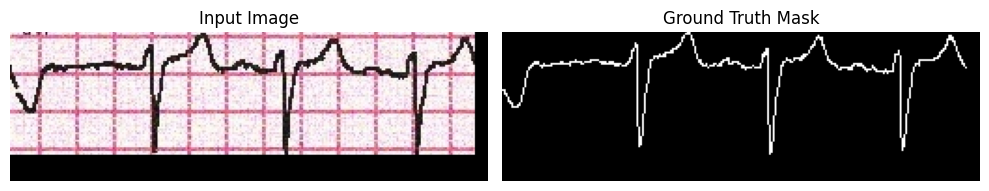

In [7]:
sample_batch = next(iter(train_loader))
images, masks, hs, ws = sample_batch

print(f"Images shape: {images.shape}")
print(f"Masks shape: {masks.shape}")
print(f"Image range: [{images.min():.3f}, {images.max():.3f}]")
print(f"Mask range: [{masks.min():.3f}, {masks.max():.3f}]")
print(f"Mask unique values: {masks.unique()}")
print(f"Original sizes: h={hs}, w={ws}")

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

img_show = images[0].cpu().permute(1, 2, 0).numpy()
# img_show = img_show * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
img_show = np.clip(img_show, 0, 1)

axes[0].imshow(img_show)
axes[0].set_title('Input Image')
axes[0].axis('off')

axes[1].imshow(masks[0, 0].cpu().numpy(), cmap='gray')
axes[1].set_title('Ground Truth Mask')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('sample_data.png')
plt.show()

In [8]:
img, mask, orig_h, orig_w = train_dataset[3]
print("Image shape:", img.shape)
print("Mask shape:", mask.shape)
print("Original size:", orig_h, orig_w)

Image shape: torch.Size([3, 32, 256])
Mask shape: torch.Size([1, 32, 256])
Original size: 27 247


## Pretrained model

In [9]:
# def calculate_iou(pred, target, threshold=0.5, eps=1e-7):
#     """
#     pred: (B, 1, H, W) after sigmoid
#     target: (B, 1, H, W) binary mask
#     """
#     pred = (pred > threshold).float() # because sigmoid outputs continous values. this result is 0.0 or 1.0
#     target = (target > threshold).float() # the dataset already use true binary mask image so no threshold needed

#     pred = pred.view(pred.size(0), -1)
#     target = target.view(target.size(0), -1)

#     intersection = (pred * target).sum(dim=1)
#     union = pred.sum(dim=1) + target.sum(dim=1) - intersection

#     iou = (intersection + eps) / (union + eps)

#     return iou.mean().item()
# def calculate_iou(pred, target, eps=1e-7):
#     """
#     Soft IoU (NO threshold) — correct for thin ECG segmentation
#     pred   : (B, 1, H, W) after sigmoid
#     target : (B, 1, H, W) binary or soft mask
#     """
#     pred = pred.view(pred.size(0), -1)
#     target = target.view(target.size(0), -1)

#     intersection = (pred * target).sum(dim=1)
#     union = pred.sum(dim=1) + target.sum(dim=1) - intersection

#     iou = (intersection + eps) / (union + eps)
#     return iou.mean().item()
import torch
import torch.nn.functional as F

def calculate_iou(pred, target, threshold=0.5, tol=1, eps=1e-7):
    """
    Tolerant IoU for thin ECG segmentation
    pred   : (B,1,H,W) after sigmoid
    target : (B,1,H,W) binary mask
    """

    pred_b = (pred > threshold).float()
    gt_b   = (target > 0.5).float()

    # 2. Dilate both masks for tolerance
    kernel = torch.ones((1, 1, 2*tol+1, 2*tol+1), device=pred.device)

    pred_d = F.conv2d(pred_b, kernel, padding=tol) > 0
    gt_d   = F.conv2d(gt_b,  kernel, padding=tol) > 0

    pred_d = pred_d.float().view(pred_d.size(0), -1)
    gt_d   = gt_d.float().view(gt_d.size(0), -1)

    intersection = (pred_d * gt_d).sum(dim=1)
    union = pred_d.sum(dim=1) + gt_d.sum(dim=1) - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()


In [10]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth
    
    def forward(self, predictions, targets):
        # Apply sigmoid to get probabilities
        predictions = torch.sigmoid(predictions)
        
        # predictions = predictions.view(-1)
        # targets = targets.view(-1)

        # flatten per image, not the whole batch
        predictions = predictions.view(predictions.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (predictions * targets).sum(dim=1)
        dice = (2. * intersection + self.smooth) / (predictions.sum(dim=1) + targets.sum(dim=1) + self.smooth)
        
        return 1 - dice.mean()

In [11]:
class BCEDiceLoss(nn.Module):
    """
    Loss function from the paper:
    L_seg = L_Dice + 0.5 * L_BCE
    """
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss() # need raw logits
        self.dice = DiceLoss()
    
    def forward(self, predictions, targets):
        bce_loss = self.bce(predictions, targets)
        dice_loss = self.dice(predictions, targets)
        return dice_loss + 0.5 * bce_loss

In [12]:
import matplotlib.pyplot as plt
import gc

model = smp.Unet(
    encoder_name="resnet34",       
    encoder_weights="imagenet",  
    in_channels=3,                 
    classes=1,                     
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
criterion = BCEDiceLoss()

# optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer, mode='min', patience=3, factor=0.1, verbose=True
# )
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=3, factor=0.5, verbose=True
)

num_epochs = 30
best_val_loss = float('inf') # infinity since val_loss will always be smaller than inf on the first epoch.
train_losses = []
train_ious = []
val_losses = []
val_ious = []

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [13]:
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_iou = 0.0
    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}] Training", leave=False)
    
    for images, masks, h, w in loop:
        images = images.to(device, dtype=torch.float32)
        masks  = masks.to(device, dtype=torch.float32)
        
        optimizer.zero_grad()
        outputs = model(images)  # Outputs are logits
        loss = criterion(outputs, masks) 
        loss.backward()
        optimizer.step()

        outputs_prob = torch.sigmoid(outputs)
        
        train_loss += loss.item() * images.size(0)
        train_iou  += calculate_iou(outputs_prob, masks) * images.size(0)

        loop.set_postfix(
            train_loss=loss.item(),
            train_iou=train_iou / ((loop.n + 1) * images.size(0))
        )

    train_loss /= len(train_loader.dataset)
    train_iou  /= len(train_loader.dataset)
    
    train_losses.append(train_loss)
    train_ious.append(train_iou)
    
    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    loop_val = tqdm(val_loader, desc=f"Epoch [{epoch+1}/{num_epochs}] Validation", leave=False)
    
    with torch.no_grad():
        for images, masks, h, w in loop_val:
            images = images.to(device, dtype=torch.float32)
            masks  = masks.to(device, dtype=torch.float32)
            
            outputs = model(images)  # Logits
            loss = criterion(outputs, masks)
            
            outputs_prob = torch.sigmoid(outputs)
            # if epoch == 0:  # only test in first epoch to avoid spam
            #     thresholds = [0.3, 0.4, 0.5, 0.6]
            #     gt_debug = masks[0, 0].cpu().numpy() > 0.5
            
            #     for t in thresholds:
            #         pred_debug = (outputs_prob[0, 0] > t).cpu().numpy()
            #         inter = np.logical_and(gt_debug, pred_debug).sum()
            #         union = np.logical_or(gt_debug, pred_debug).sum()
            #         iou_t = 1.0 if union == 0 else inter / union
            #         print(f"[DEBUG] Threshold {t:.1f} → IoU {iou_t:.4f}")
            # if epoch == 0:
            #     gt_ratio = (masks[0, 0] > 0.5).float().mean().item()
            #     pred_ratio = (outputs_prob[0, 0] > 0.5).float().mean().item()
            #     print(f"[DEBUG] GT ratio: {gt_ratio:.4f} | Pred ratio: {pred_ratio:.4f}")
            
            val_loss += loss.item() * images.size(0)
            val_iou += calculate_iou(outputs_prob, masks) * images.size(0)
            
            loop_val.set_postfix(
                val_loss=val_loss/len(val_loader.dataset), 
                val_iou=val_iou/len(val_loader.dataset)
            )
    
    val_loss /= len(val_loader.dataset)
    val_iou /= len(val_loader.dataset)
    val_losses.append(val_loss)
    val_ious.append(val_iou)
    
    scheduler.step(val_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Train IoU: {train_iou:.4f} | Val Loss: {val_loss:.4f} | Val IoU: {val_iou:.4f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_losses': train_losses,
            'train_ious': train_ious, 
            'val_losses': val_losses,
            'val_ious': val_ious,
            'val_loss': val_loss,
            'val_iou': val_iou,
            'best_val_loss': best_val_loss,
            'learning_rate': optimizer.param_groups[0]['lr']
        }, 'best_unet_ecg.pth')
        print(f"Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")

print(f"Best validation loss: {best_val_loss:.4f}")

Epoch 1/30 | Train Loss: 0.3803 | Train IoU: 0.7826 | Val Loss: 0.3653 | Val IoU: 0.7967
Val Loss: 0.3653, Val IoU: 0.7967


Epoch 2/30 | Train Loss: 0.3028 | Train IoU: 0.8241 | Val Loss: 0.2833 | Val IoU: 0.8332
Val Loss: 0.2833, Val IoU: 0.8332


Epoch 3/30 | Train Loss: 0.2821 | Train IoU: 0.8348 | Val Loss: 0.2701 | Val IoU: 0.8410
Val Loss: 0.2701, Val IoU: 0.8410


Epoch 4/30 | Train Loss: 0.2706 | Train IoU: 0.8406 | Val Loss: 0.2715 | Val IoU: 0.8381


Epoch 5/30 | Train Loss: 0.2637 | Train IoU: 0.8444 | Val Loss: 0.2603 | Val IoU: 0.8467
Val Loss: 0.2603, Val IoU: 0.8467


Epoch 6/30 | Train Loss: 0.2606 | Train IoU: 0.8459 | Val Loss: 0.2585 | Val IoU: 0.8474
Val Loss: 0.2585, Val IoU: 0.8474


... (20 outputs left out)

Epoch 27/30 | Train Loss: 0.2255 | Train IoU: 0.8660 | Val Loss: 0.2433 | Val IoU: 0.8551


Epoch 28/30 | Train Loss: 0.2242 | Train IoU: 0.8668 | Val Loss: 0.2374 | Val IoU: 0.8600


Epoch 29/30 | Train Loss: 0.2236 | Train IoU: 0.8670 | Val Loss: 0.2394 | Val IoU: 0.8582


Epoch 30/30 | Train Loss: 0.2148 | Train IoU: 0.8720 | Val Loss: 0.2339 | Val IoU: 0.8604
Val Loss: 0.2339, Val IoU: 0.8604
Best validation loss: 0.2339


In [14]:
# def evaluate_on_train_one_epoch(model, train_loader, device, criterion, threshold=0.5):
#     model.eval()

#     total_loss = 0.0
#     total_iou = 0.0
#     total_precision = 0.0
#     total_recall = 0.0
#     total_f1 = 0.0
#     n_samples = 0

#     eps = 1e-7

#     with torch.no_grad():
#         for images, masks, _, _ in train_loader:
#             images = images.to(device, dtype=torch.float32)
#             masks  = masks.to(device, dtype=torch.float32)

#             outputs = model(images)
#             loss = criterion(outputs, masks)
            
#             probs = torch.sigmoid(outputs)
#             preds = (probs > threshold).float()

#             B = images.size(0)

#             preds_f = preds.view(B, -1)
#             masks_f = masks.view(B, -1)

#             TP = (preds_f * masks_f).sum(dim=1)
#             FP = (preds_f * (1 - masks_f)).sum(dim=1)
#             FN = ((1 - preds_f) * masks_f).sum(dim=1)

#             iou = (TP + eps) / (TP + FP + FN + eps)
#             precision = (TP + eps) / (TP + FP + eps)
#             recall = (TP + eps) / (TP + FN + eps)
#             f1 = 2 * (precision * recall) / (precision + recall + eps)

#             total_loss += loss.item() * B
#             total_iou += iou.sum().item()
#             total_precision += precision.sum().item()
#             total_recall += recall.sum().item()
#             total_f1 += f1.sum().item()
#             n_samples += B

#     avg_loss = total_loss / n_samples
#     avg_iou = total_iou / n_samples
#     avg_precision = total_precision / n_samples
#     avg_recall = total_recall / n_samples
#     avg_f1 = total_f1 / n_samples

#     print("===== TRAIN SET EVALUATION (ONE EPOCH) =====")
#     print(f"Loss      : {avg_loss:.4f}")
#     print(f"IoU       : {avg_iou:.4f}")
#     print(f"Precision : {avg_precision:.4f}")
#     print(f"Recall    : {avg_recall:.4f}")
#     print(f"F1-score  : {avg_f1:.4f}")

#     return avg_iou, avg_precision, avg_recall, avg_f1


In [15]:
# train_iou, train_prec, train_rec, train_f1 = evaluate_on_train_one_epoch(
#     model, train_loader, device, criterion
# )

In [16]:
# def visualize_iou_samples(model, dataloader, device, num_samples=4, threshold=0.5):
#     model.eval()
#     shown = 0

#     with torch.no_grad():
#         for images, masks, _, _ in dataloader:
#             images = images.to(device, dtype=torch.float32)
#             masks  = masks.to(device, dtype=torch.float32)

#             outputs = model(images)
#             probs = torch.sigmoid(outputs)
#             preds = (probs > threshold).float()

#             for i in range(images.size(0)):
#                 img  = images[i].permute(1, 2, 0).cpu().numpy()
#                 gt   = masks[i][0].cpu().numpy()
#                 pr   = preds[i][0].cpu().numpy()

#                 iou = calculate_iou(
#                     preds[i:i+1],
#                     masks[i:i+1]
#                 )

#                 plt.figure(figsize=(12, 4))

#                 plt.subplot(1, 3, 1)
#                 plt.imshow(img)
#                 plt.title("Input Image")
#                 plt.axis("off")

#                 plt.subplot(1, 3, 2)
#                 plt.imshow(gt, cmap="gray")
#                 plt.title("Ground Truth")
#                 plt.axis("off")

#                 plt.subplot(1, 3, 3)
#                 plt.imshow(pr, cmap="gray")
#                 plt.title(f"Prediction | IoU={iou:.4f}")
#                 plt.axis("off")

#                 plt.show()

#                 shown += 1
#                 if shown >= num_samples:
#                     return


In [17]:
# visualize_iou_samples(model, val_loader, device, num_samples=5)


In [18]:
# def visualize_predictions(model, data_loader, device, num_samples=4, split_name="Validation"):
#     """Visualize predictions with IoU overlay"""
#     model.eval()
    
#     # Collect samples first (memory efficient)
#     samples_data = []
    
#     with torch.no_grad():
#         for images, masks, heights, widths in data_loader:
#             if len(samples_data) >= num_samples:
#                 break
                
#             images = images.to(device, dtype=torch.float32)
#             masks = masks.to(device, dtype=torch.float32)
            
#             outputs = model(images)
#             outputs_prob = torch.sigmoid(outputs)
#             preds = (outputs_prob > 0.5).float()
            
#             # Process each image in the batch
#             for i in range(images.size(0)):
#                 if len(samples_data) >= num_samples:
#                     break
                
#                 h = heights[i].item() if torch.is_tensor(heights[i]) else int(heights[i])
#                 w = widths[i].item() if torch.is_tensor(widths[i]) else int(widths[i])
                
#                 # Move to CPU to free GPU memory
#                 img = images[i].cpu().permute(1, 2, 0).numpy()[:h, :w]
#                 mask_gt = masks[i, 0].cpu().numpy()[:h, :w]
#                 mask_pred = preds[i, 0].cpu().numpy()[:h, :w]

#                 mask_gt = (mask_gt > 0.5)
#                 mask_pred = (mask_pred > 0.5)
                
#                 # Calculate IoU for this sample
#                 intersection = np.logical_and(mask_gt, mask_pred).sum()
#                 union = np.logical_or(mask_gt, mask_pred).sum()
#                 if union == 0:
#                     iou = 1.0
#                 else:
#                     iou = intersection / union

#                 samples_data.append({
#                     'img': img,
#                     'mask_gt': mask_gt,
#                     'mask_pred': mask_pred,
#                     'iou': iou
#                 })
            
#             # Clear GPU memory after each batch
#             del images, masks, outputs, outputs_prob, preds
#             torch.cuda.empty_cache()
    
#     # Now plot all samples
#     fig, axes = plt.subplots(len(samples_data), 4, figsize=(16, 4*len(samples_data)))
#     if len(samples_data) == 1:
#         axes = axes.reshape(1, -1)
    
#     for idx, sample in enumerate(samples_data):
#         img = sample['img']
#         mask_gt = sample['mask_gt']
#         mask_pred = sample['mask_pred']
#         iou = sample['iou']
        
#         # Plot 1: Original Image
#         axes[idx, 0].imshow(img)
#         axes[idx, 0].set_title(f'Original Image')
#         axes[idx, 0].axis('off')
        
#         # Plot 2: Ground Truth Mask
#         axes[idx, 1].imshow(img)
#         axes[idx, 1].imshow(mask_gt, alpha=0.5, cmap='Reds')
#         axes[idx, 1].set_title('Ground Truth')
#         axes[idx, 1].axis('off')
        
#         # Plot 3: Predicted Mask
#         axes[idx, 2].imshow(img)
#         axes[idx, 2].imshow(mask_pred, alpha=0.5, cmap='Blues')
#         axes[idx, 2].set_title('Prediction')
#         axes[idx, 2].axis('off')
        
#         # Plot 4: Overlay (Green=Correct, Red=FP, Blue=FN)
#         overlay = np.zeros((*mask_gt.shape, 3))
#         # True Positives (Green)
#         tp = np.logical_and(mask_gt == 1, mask_pred == 1)
#         overlay[tp] = [0, 1, 0]
#         # False Positives (Red)
#         fp = np.logical_and(mask_gt == 0, mask_pred == 1)
#         overlay[fp] = [1, 0, 0]
#         # False Negatives (Blue)
#         fn = np.logical_and(mask_gt == 1, mask_pred == 0)
#         overlay[fn] = [0, 0, 1]
        
#         axes[idx, 3].imshow(img)
#         axes[idx, 3].imshow(overlay, alpha=0.6)
#         axes[idx, 3].set_title(f'Overlay (IoU: {iou:.4f})\nGreen=TP, Red=FP, Blue=FN')
#         axes[idx, 3].axis('off')
    
#     plt.suptitle(f'{split_name} Set - Sample Predictions', fontsize=16, y=1.00)
#     plt.tight_layout()
#     plt.savefig(f'{split_name.lower()}_predictions.png', dpi=150, bbox_inches='tight')
#     plt.show()
#     plt.close()
    
#     # Clean up
#     del samples_data
#     gc.collect()

In [19]:
print("Evaluating on Test Set...")

model.eval()
test_loss = 0.0
test_iou = 0.0

with torch.no_grad():
    loop_test = tqdm(test_loader, desc="Testing")
    for images, masks, h, w in loop_test:
        images = images.to(device, dtype=torch.float32)
        masks  = masks.to(device, dtype=torch.float32)
        
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        outputs_prob = torch.sigmoid(outputs)
        
        test_loss += loss.item() * images.size(0)
        test_iou += calculate_iou(outputs_prob, masks) * images.size(0)
        
        loop_test.set_postfix(
            test_loss=test_loss/len(test_loader.dataset), 
            test_iou=test_iou/len(test_loader.dataset)
        )

test_loss /= len(test_loader.dataset)
test_iou /= len(test_loader.dataset)


print(f"\nTest Results:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.4f}")

Evaluating on Test Set...


Testing: 100%|██████████| 1414/1414 [01:48<00:00, 12.99it/s, test_iou=0.86, test_loss=0.235]


Test Results:
Test Loss: 0.2351
Test IoU: 0.8604


In [20]:
def visualize_predictions(model, data_loader, device, num_samples=4, split_name="Validation"):
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    import cv2
    import gc
    
    model.eval()
    samples_data = []
    
    with torch.no_grad():
        for images, masks, heights, widths in data_loader:
            if len(samples_data) >= num_samples:
                break
            
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)
            
            outputs = model(images)
            outputs_prob = torch.sigmoid(outputs)
            preds = (outputs_prob > 0.5).float()
            
            for i in range(images.size(0)):
                if len(samples_data) >= num_samples:
                    break
                
                h = int(heights[i])
                w = int(widths[i])
                
                img = images[i].cpu().permute(1, 2, 0).numpy()[:h, :w]
                mask_gt = masks[i, 0].cpu().numpy()[:h, :w]
                mask_pred = preds[i, 0].cpu().numpy()[:h, :w]
                
                # Resize masks if needed
                if mask_gt.shape != img.shape[:2]:
                    mask_gt = cv2.resize(mask_gt, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                if mask_pred.shape != img.shape[:2]:
                    mask_pred = cv2.resize(mask_pred, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                
                mask_gt_bin = (mask_gt > 0.5).astype(np.uint8)
                mask_pred_bin = (mask_pred > 0.5).astype(np.uint8)
                
                # IoU calculation
                iou = calculate_iou(
                    torch.from_numpy(mask_pred_bin)[None, None].float().to(device),
                    torch.from_numpy(mask_gt_bin)[None, None].float().to(device)
                )
                
                samples_data.append({
                    'img': img,
                    'mask_gt': mask_gt_bin,
                    'mask_pred': mask_pred_bin,
                    'iou': iou
                })
        
        del images, masks, outputs, outputs_prob, preds
        torch.cuda.empty_cache()
    
    # Plotting with shift
    fig, axes = plt.subplots(len(samples_data), 4, figsize=(16, 4 * len(samples_data)))
    if len(samples_data) == 1:
        axes = axes.reshape(1, -1)
    
    SHIFT_RIGHT = 3  # Horizontal shift (right)
    SHIFT_DOWN = 2   # Vertical shift (down) - adjust this value
    
    for idx, sample in enumerate(samples_data):
        img = sample['img']
        mask_gt = sample['mask_gt']
        mask_pred = sample['mask_pred']
        iou = sample['iou']
        
        # Create shifted masks (right and down)
        mask_gt_shifted = np.zeros_like(mask_gt)
        mask_pred_shifted = np.zeros_like(mask_pred)
        
        if SHIFT_RIGHT < mask_gt.shape[1] and SHIFT_DOWN < mask_gt.shape[0]:
            mask_gt_shifted[SHIFT_DOWN:, SHIFT_RIGHT:] = mask_gt[:-SHIFT_DOWN, :-SHIFT_RIGHT]
            mask_pred_shifted[SHIFT_DOWN:, SHIFT_RIGHT:] = mask_pred[:-SHIFT_DOWN, :-SHIFT_RIGHT]
        
        # Image only
        axes[idx, 0].imshow(img)
        axes[idx, 0].set_title("Image")
        axes[idx, 0].axis('off')
        
        # Ground Truth overlay (shifted)
        axes[idx, 1].imshow(img)
        axes[idx, 1].imshow(mask_gt_shifted, alpha=0.5, cmap='Reds')
        axes[idx, 1].set_title("Ground Truth")
        axes[idx, 1].axis('off')
        
        # Prediction overlay (shifted)
        axes[idx, 2].imshow(img)
        axes[idx, 2].imshow(mask_pred_shifted, alpha=0.5, cmap='Blues')
        axes[idx, 2].set_title("Prediction")
        axes[idx, 2].axis('off')
        
        # Overlay (TP/FP/FN) - shifted
        overlay = np.zeros((*mask_gt.shape, 3), dtype=np.float32)
        tp = (mask_gt_shifted == 1) & (mask_pred_shifted == 1)
        fp = (mask_gt_shifted == 0) & (mask_pred_shifted == 1)
        fn = (mask_gt_shifted == 1) & (mask_pred_shifted == 0)
        
        overlay[tp] = [0, 1, 0]   # green
        overlay[fp] = [1, 0, 0]   # red
        overlay[fn] = [0, 0, 1]   # blue
        axes[idx, 3].imshow(img)
        axes[idx, 3].imshow(overlay, alpha=0.6)
        axes[idx, 3].set_title(f"Overlay IoU: {iou:.4f}\nGreen=TP, Red=FP, Blue=FN ")
        axes[idx, 3].axis('off')
    
    plt.suptitle(f'{split_name} Set - Sample Predictions', fontsize=16)
    plt.tight_layout()
    plt.savefig(f'{split_name.lower()}_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    del samples_data
    gc.collect()


Visualizing test set predictions...


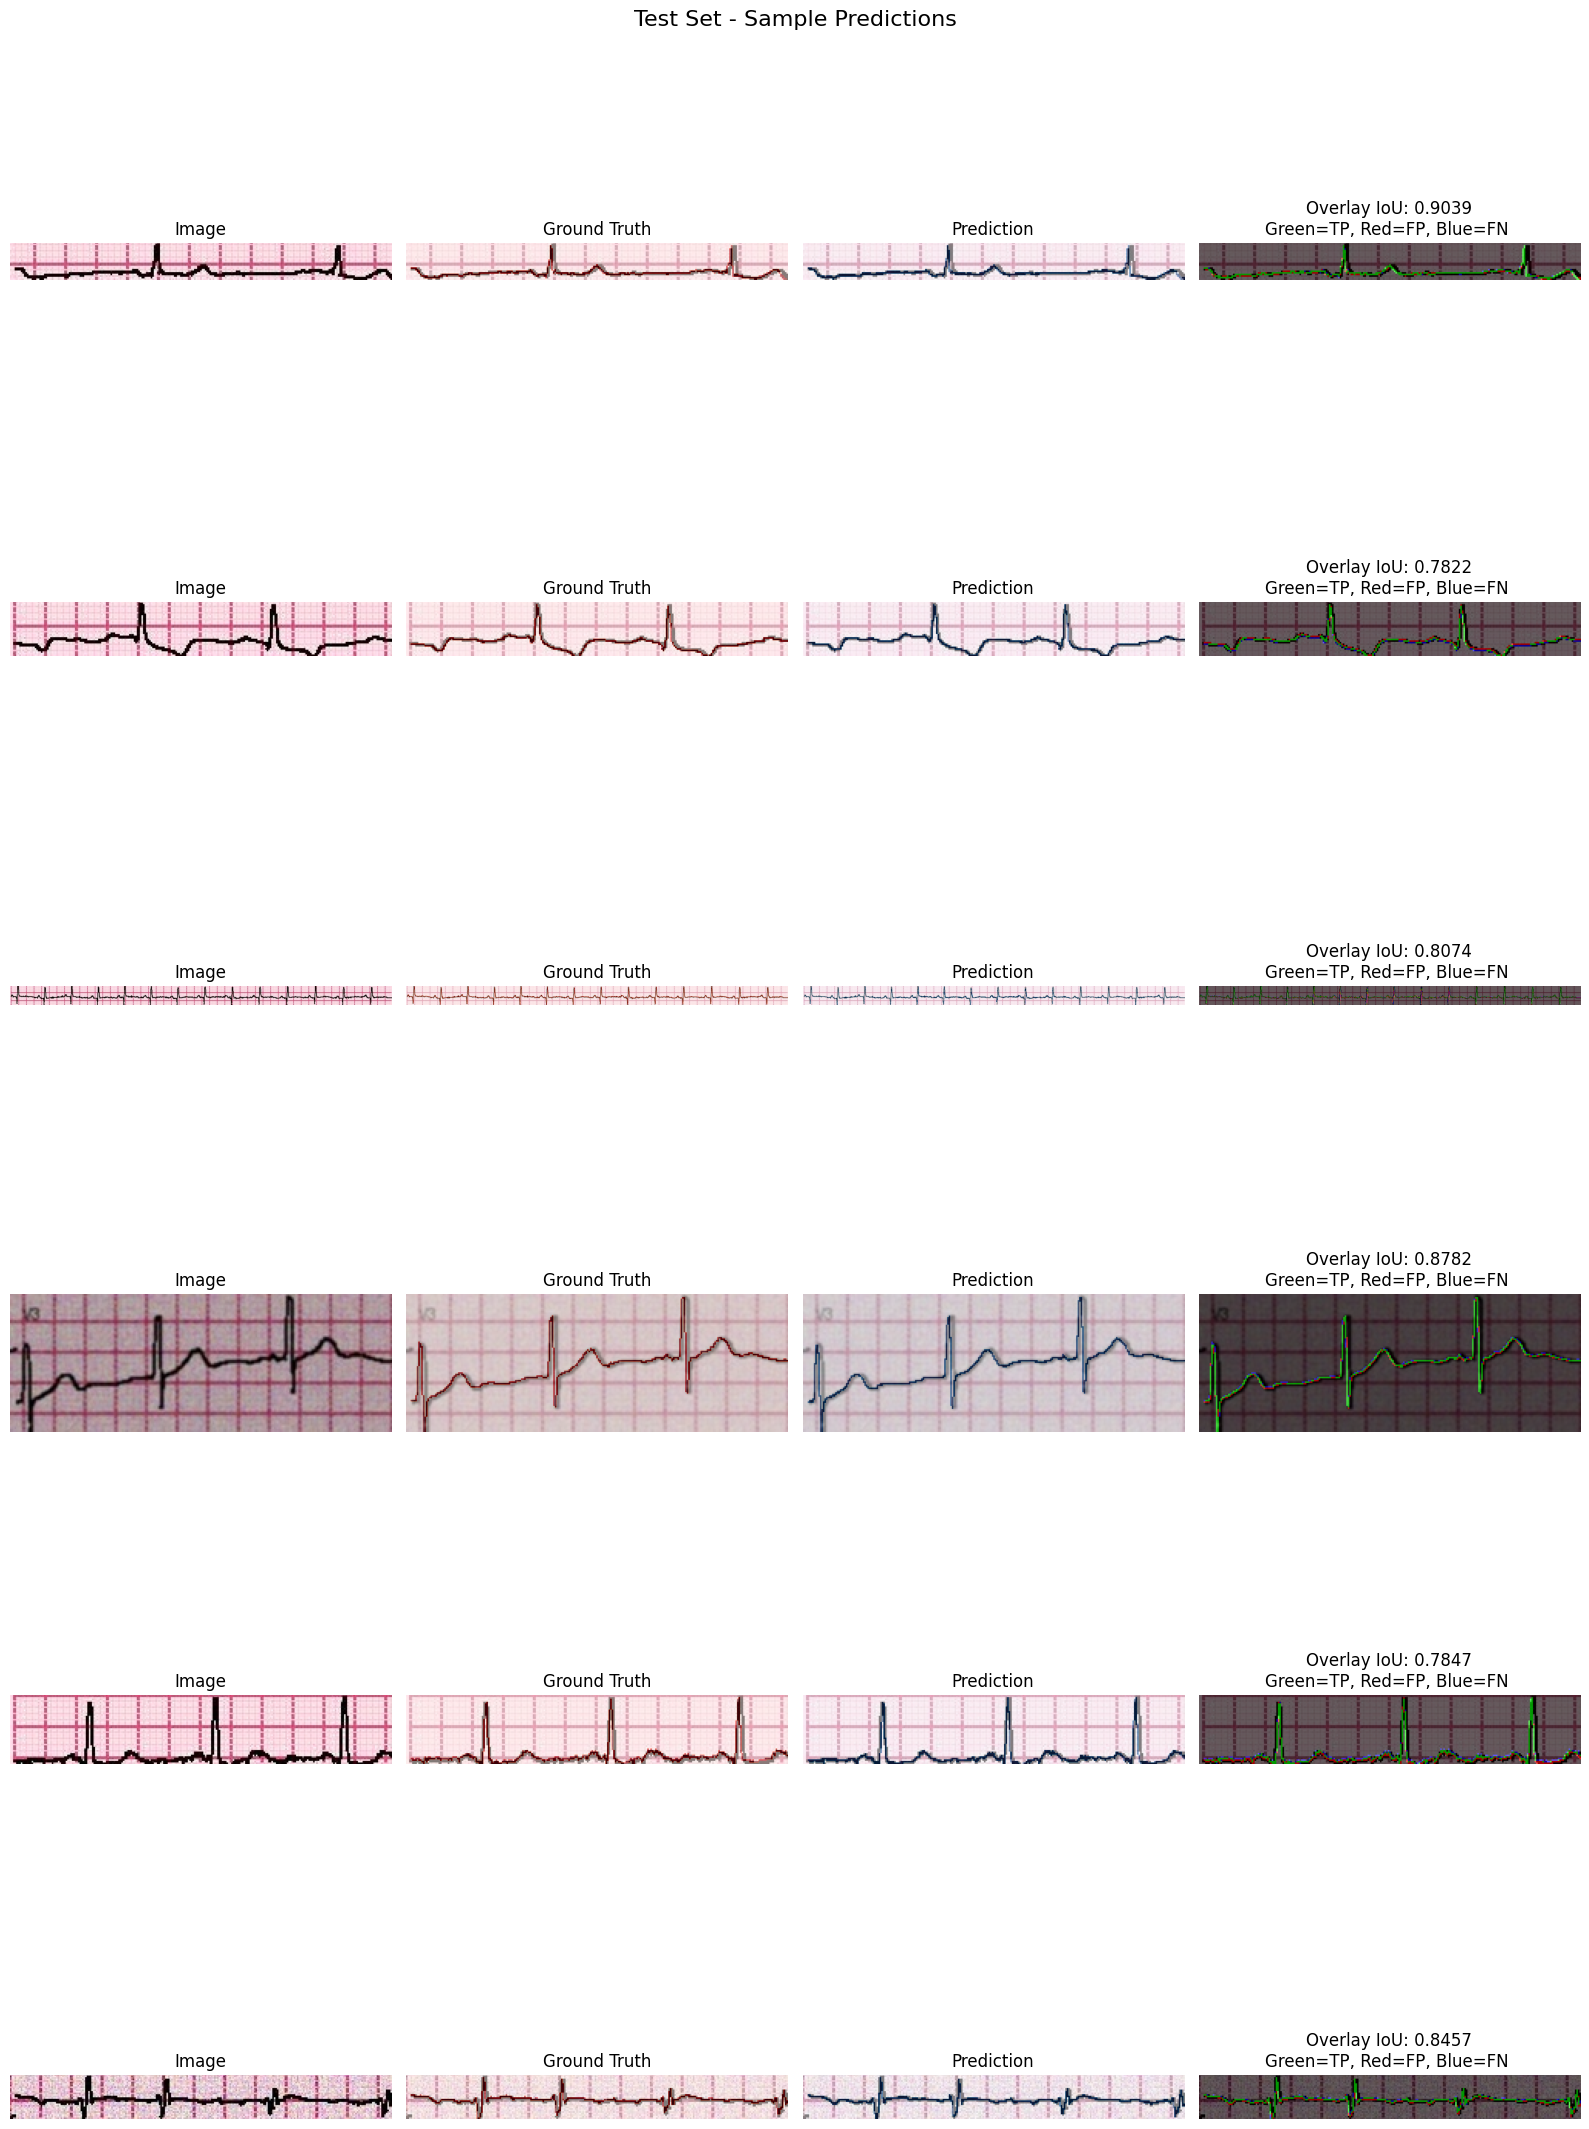


Final model saved


In [21]:
print("\nVisualizing test set predictions...")
visualize_predictions(model, test_loader, device, num_samples=6, split_name="Test")

# Save final results including test metrics
torch.save({
    'epoch': num_epochs - 1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'val_ious': val_ious,
    'best_val_loss': best_val_loss,
    'test_loss': test_loss,
    'test_iou': test_iou,
    'learning_rate': optimizer.param_groups[0]['lr']
}, 'final_unet_ecg_with_test.pth')

print(f"\nFinal model saved")

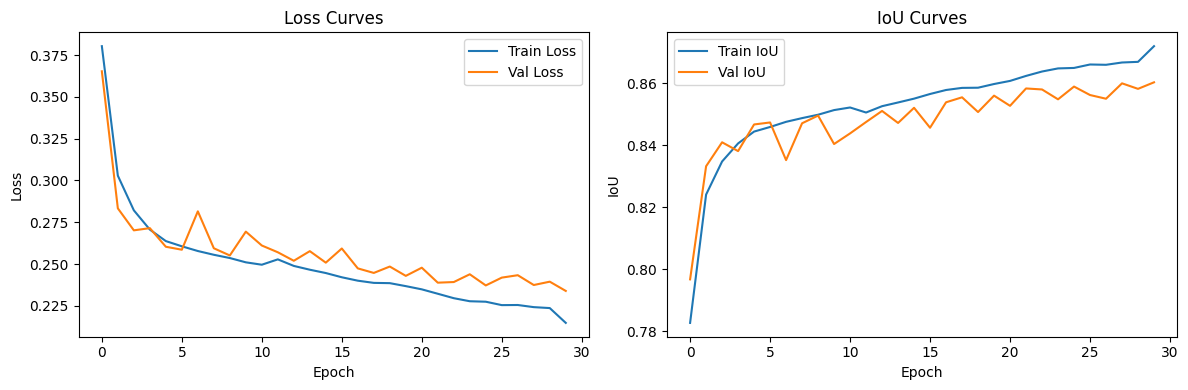

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(train_ious, label='Train IoU')
plt.plot(val_ious, label='Val IoU')
plt.xlabel('Epoch')
plt.ylabel('IoU')
plt.legend()
plt.title('IoU Curves')

plt.tight_layout()
plt.savefig('training_progress.png')
plt.show()